# Preprocessing

In this tutorial we will show how to construct a preprocessing pipeline to "prepare" your recording prior to spike sorting.

The preprocessing steps we will explore in this chapter are:

* **filtering**: Filters out low-frequency oscillations (e.g. 50-60 Hz noise) and high-frequency oscillations (e.g. noise spikes) from the data. Applied separately per channel.

* **bad channel detection**: Automatically detect channels that are dead, noisy or out-of-brain. These bad channels can be removed or interpolated (i.e ‘filled in’ using the data from surrounding channels).

* **denoising**: Removes noise that takes the form of stripes through the data (i.e. occurring on all channels for a short period of time). This is applied across all channels, separately per time point.

* **saturation detection**: Detect periods in the recording where the electronics were saturated (i.e. the voltage exceeds the range of the recording electronics). We detect saturation periods on the raw recording, and set any detected periods to zero after filtering.

* **motion correction**: A step to account for physical drift of the probe in the brain. Attempts to estimate the drift and interpolate the channels (having the effect of shifting the signal up or down the probe) to account for it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.widgets as sw


In [2]:
import os
os.getcwd()

'/home/pierre/github/school_neuralnet_paris_2026/notebooks_sorting'

In [3]:
%matplotlib widget

In [10]:
# Modify this to where you downloaded your datasets
base_data_folder = Path("/home/pierre/data/school_2026")
results_folder = Path("/home/pierre/results/school_2026")

In [8]:
si.set_global_job_kwargs(n_jobs=4)

In [11]:
recording_name = 'dandiset-000939-90s'

path_to_recording = base_data_folder / recording_name

recording = si.load(path_to_recording)

In [12]:
recording

BinaryFolderRecording: 64 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                       90.00s (1.50 minutes) - int16 dtype - 219.73 MiB

In [13]:
recording = spre.depth_order(recording)

Let's first take a look at the "raw" traces. We'll write a helper function now which will help us plot side-by-side comparisons later on.

In [14]:
sw.set_default_plotter_backend("ipywidgets")

TIME_RANGE = (49, 49.02)

def plot_prepro(recordings, time_range, return_in_uV=True, clim=None):
    """
    Plot multiple recordings in subplots.

    Parameters
    ----------
    recordings :
        A dictionary of recordings. The recordings will be plot and
        the corresponding keys used as plot titles.
    time_range: 
        A tuple with the (start, stop) times of the data to plot.
    clim:
        A tuple with the (min, max) colour limits for the heatmap.
    """
    fig, axes = plt.subplots(
        1, len(recordings), 
        figsize=(6 * len(recordings), 5), 
        squeeze=False,
        layout="constrained",
    )

    # Grab the first (and only) row of axes
    axes = axes[0, :]

    for idx, (name, recording) in enumerate(recordings.items()):
        
        ax = axes[idx]

        sw.plot_traces(
            recording,
            time_range=time_range,
            mode="map",  # plot as a heatmap
            ax=ax,
            with_colorbar=True,
            return_in_uV=True,
            clim=clim,
            backend="matplotlib"
        )
        ax.set_title(name)
        ax.tick_params(axis="x", rotation=45)

In [15]:
w = sw.plot_traces(recording, mode="map", backend="ipywidgets")

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

Mmm...it looks very noisy...is there any good signal there? We'll see how preprocessing can drastically change the situation!


The `spikeinterface.preprocessing` module includes a large library of preprocessing functions. We'll only see a few of them, but we encourage you to check out and read what's available!

- [Preprocessing docs](https://spikeinterface.readthedocs.io/en/latest/modules/preprocessing.html)
- [API reference](https://spikeinterface.readthedocs.io/en/latest/api.html#module-spikeinterface.preprocessing)

### Step 1: Filtering

Filtering is usually the first step in a preprocessing pipeline. Most acquisition systems record wide-band data. Filtering allow us to focus on the frequency content that contains spikes.

It is important to get rid of low frequency bands (<300 Hz) since they mainly contain Local Field Potential (LFP).
Both highpass filter (removing low frequencies) and a bandpass filter (removing low and very high frequencies) can do the job.

They both have pros and cons:
- a highpass filter might let unwanted highpass filters in your signal. However, some argue that a the spike signal is also at relatively high frequencies (>6 kHz) and this might improve spike sorting.
- a bandpass filter might dampen signals from unwanted high-frequency noise (if present), at the expense of cutting out some spike signals

For the sake of this tutorial, we will stick to bandpass filtering, which is commonly used in electrophysiology data.

In [16]:
recording_bp = spre.bandpass_filter(recording, freq_min=300, freq_max=6000)

Applying the filtering steps is **extremely fast**! How is it possible that the entire traces have been filtered in a split second???
They haven't! 

SpikeInterface uses *lazy* processing, which means that any processing step is applied only when needed. This allow one to construct preprocessing chains, which describe the processing that the traces will go through when retrieved. The `SpikeInterface.Recording` object carries information about what processing steps were applied to it.

In [17]:
recording_bp

BandpassFilterRecording: 64 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                         90.00s (1.50 minutes) - int16 dtype - 219.73 MiB

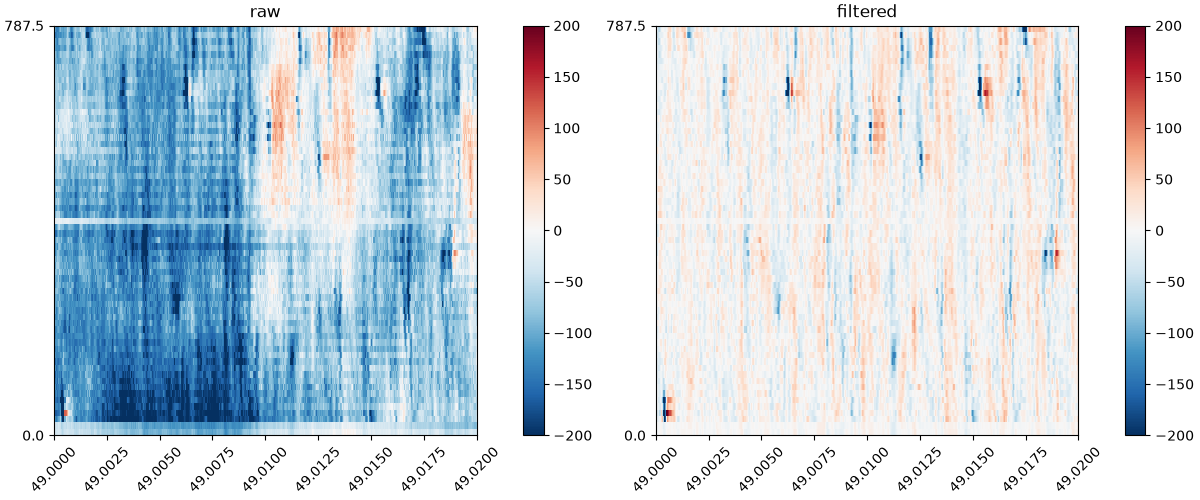

In [18]:
plot_prepro(
    {"raw": recording, "filtered": recording_bp}, 
    time_range=TIME_RANGE
)

In [19]:
w = sw.plot_traces(
    dict(raw=recording, bp=recording_bp), mode="map", clim=(-500, 500)
)

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

### Step 1b: Phase-shift (Neuropixels only)

Some devices have fewer Analog-to-Digital Converters (ADCs) than number of channels. This means that multiple channels are multiplexed, i.e., sequentially sampled, within the same sampling period. Therefore, the channels sampled by the same ADC have a small sub-sampling-period delay between them.
We can correct for these delays using the [`phase_shift`](https://spikeinterface.readthedocs.io/en/latest/api.html#spikeinterface.preprocessing.phase_shift) method.

Phase shift can be applied when the `inter_sample_shift` property is available. This property is automatically loaded for Neuropixels probes.

In [20]:
needs_phase_shift = "inter_sample_shift" in recording_bp.get_property_keys()
print("Inter sample shift available?", needs_phase_shift)

if needs_phase_shift:
    recording_ps = spre.phase_shift(recording_bp)
    w = sw.plot_traces(
        dict(bp=recording_bp, ps=recording_ps),
    )
    recording_processed = recording_ps
else:
    print("The recording doesn't need phase shift")
    recording_processed = recording_bp

Inter sample shift available? False
The recording doesn't need phase shift


The additional alignment, despite being small, can help in further steps, such as denoising, especially in the presence of highly synchronized and probe-wide noise (aka "stripes").

### Step 2: Detecting bad channels

Bad channels can be "broken" electrodes with an abnormally high or low activity. Bad channels can also show up when not the entire probe is inserted in the brain, so that the channels at the top will display different statistics than the rest.

The `detect_bad_channels` implements several methods to detect bad channels. The most advanced method is designed for needle-like probes and use both PSD and coherence across channels to label channels as "good", "noise" (activity abnormally high), "dead" (activity abnormally low), or "out" (out of brain).
Other methods simply compare the noise level of each channel (as standard deviation or MAD) and if that's too high, the method flags channels as noise.

See [IBL spike sorting paper](https://figshare.com/articles/online_resource/Spike_sorting_pipeline_for_the_International_Brain_Laboratory/19705522/4?file=49783080) for more details.

In [21]:
# spre.detect_bad_channels?

In [22]:
bad_channel_ids_1, channel_labels_1 = spre.detect_bad_channels(recording_processed)
labels_1, counts_1 = np.unique(channel_labels_1, return_counts=True)
print("first attempt labels:\n", labels_1, counts_1)

detect_bad_channels (workers: 4 processes fork):   0%|          | 0/100 [00:00<?, ?it/s]

first attempt labels:
 ['good'] [64]


**It didn’t work!** We can still see the dead channels on our recording. Why is this?

The IBL algorithm was developed for Neuropixel probes (with 384 recording channels) but we are using Cambridge Neurotech 64-channel probes. As such, the default settings are not appropriate for our data, and we need to adjust them.

The new values were found through trial and error. n_neighbors default is 11 so we reduced it for the 64-channel Cambridge Neurotech probe. We also set outside_channels_location=“bottom”. By convention the algorithm expects out-of-brain channels at the top of the depth-ordered channels (as on Neuropixels), but by this probe’s channel-ordering convention they sit at the bottom (index 0). Finally, we reduced the thresholds through trial and error to ensure the dead and out-of-brain channels were flagged correctly (once set, this configuration should work for all recordings in this dataset, but of course we should always check).

In [23]:
bad_channel_ids, channel_labels = spre.detect_bad_channels(
    recording_processed,
    dead_channel_threshold=-0.15,
    outside_channels_location="bottom",
    outside_channel_threshold=-0.25,
    n_neighbors=5
)
labels_2, counts_2 = np.unique(channel_labels, return_counts=True)
print("second attempt labels:\n", labels_2, counts_2)

detect_bad_channels (workers: 4 processes fork):   0%|          | 0/100 [00:00<?, ?it/s]

second attempt labels:
 ['dead' 'good' 'out'] [ 2 60  2]


There is also a function to `detect_and_remove_bad_channels` in one go. Since we pre-computed bad channels, we can pass them along.
This is recommended so that out preprocessing "chain" knows that bad channeld detection + removal was applied.

In [24]:
recording_good = spre.detect_and_remove_bad_channels(
    recording_processed,
    bad_channel_ids=bad_channel_ids,
    channel_labels=channel_labels
)

In [25]:
recording_good

DetectAndRemoveBadChannelsRecording: 60 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                                     90.00s (1.50 minutes) - int16 dtype - 205.99 MiB

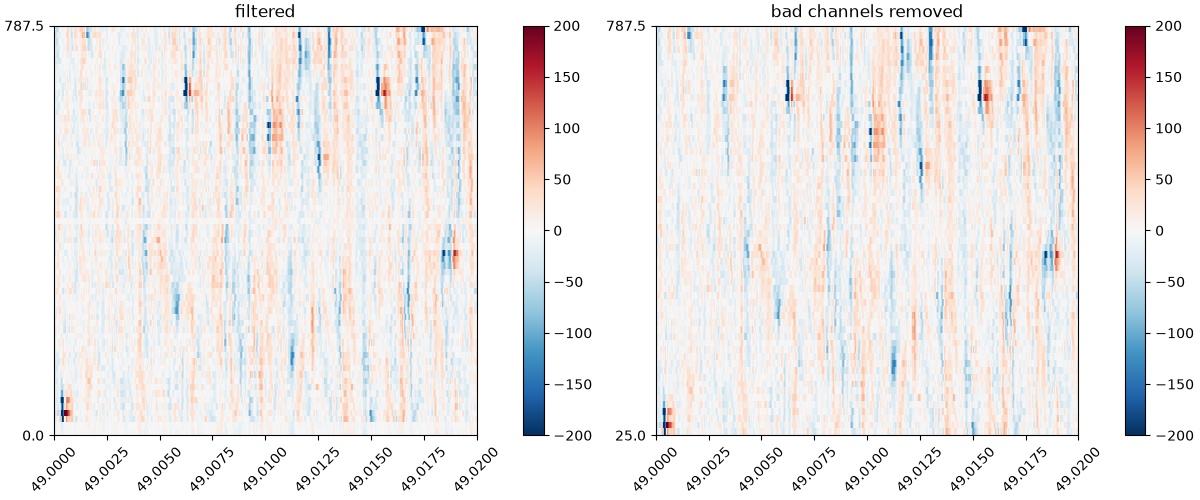

In [26]:
plot_prepro(
    {"filtered": recording_processed, 
    "bad channels removed": recording_good},
    TIME_RANGE
)

### Step 4: Denoising

After removing bad channels, we can try to further reduce noise in the traces, especially the "common mode" noise (e.g., noise shared across all/many channels).
The source of such noise is usually extrinsic (for example a lamp in your rig!) and it causes those stripes that we've seen in the plots.

We have two ways to remove these stripes, again, with pros and cons:

- Common Median Reference (CMR): CMR is very widely used and very simple! For every sample, we remove the median of all channels. If noise is shared across all channels, then it will be removed by these operation. The downside is that if some channels don't experience the shared noise, an artifact could be introduced.
- Highpass Spatial Filtering: this step instead performs a highpass filter in space. You can imagine vertical stripes as low frequency (DC) in the space dimension. The upside of this method is that it can handle partial noise shared on large subset of channels. The downside is that it can also dampen spike signals, especially when they are shared across many channels.

For today, we will focus on common median reference.

In [28]:
recording_cmr = spre.common_reference(recording_good)

In [29]:
recording_cmr

CommonReferenceRecording: 60 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                          90.00s (1.50 minutes) - int16 dtype - 205.99 MiB

In [30]:
TIME_RANGE1 = [TIME_RANGE[0] + 1, TIME_RANGE[1] + 1]

In [31]:
w = sw.plot_traces(
    dict(bp=recording_good, cmr=recording_cmr),
    mode="map",
    time_range=TIME_RANGE1,
    clim=(-500, 500)
)

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

### Step 5: Remove saturation artifacts

The electronics that record the extracellular voltage have dynamic ranges in which they operate. If the voltage exceeds this range, the equipment is said to ‘saturate’ and the recorded values are uninformative.

The working ranges are associated with the specific recording equipment, most commonly the amplifier and analog-digital converters. For Neuropixels, these electronics are contained in the probe and the probe manual specifies the input voltage range (IBL recommend a threshold of 1200 μV for NP1; NP2 probes have a wider range and are harder to saturate).

The data we are working with was recorded on a Cambridge Neurotech probe, using an Intan RHD2000-series amplifier/headstage with range -5 mV to 5 mV. Therefore, we can use SpikeInterface to detect any periods of the recording that fall outside ±5 mV (5000 μV).

We need to detect saturation events before any preprocessing has occurred, as we need the raw voltage values to determine saturation. However, we must remove these events by zeroing them out after filtering, as sharp transitions to zero can cause filter artifacts.

In [32]:
recording.annotate(saturation_threshold_uV=5000)

In [33]:
recording_zeroed  = spre.detect_and_remove_artifacts(
    recording_cmr,
    recording_to_detect=recording,
    method="saturation",    
)

detect saturation artifacts (workers: 4 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

In [34]:
recording_zeroed

DetectAndRemoveArtifactsRecording: 60 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                                   90.00s (1.50 minutes) - int16 dtype - 205.99 MiB

In [35]:
artifacts = recording_zeroed._kwargs["artifact_periods"]
artifacts

array([(0, 140661, 140864)],
      dtype=[('segment_index', '<i8'), ('start_sample_index', '<i8'), ('end_sample_index', '<i8')])

In [36]:
saturation_time_start = recording_zeroed.sample_index_to_time(artifacts["start_sample_index"][0])
saturation_time_stop = recording_zeroed.sample_index_to_time(artifacts["end_sample_index"][0])

In [37]:
SAT_TIME_RANGE = (saturation_time_start - 0.2, saturation_time_stop + 0.2)

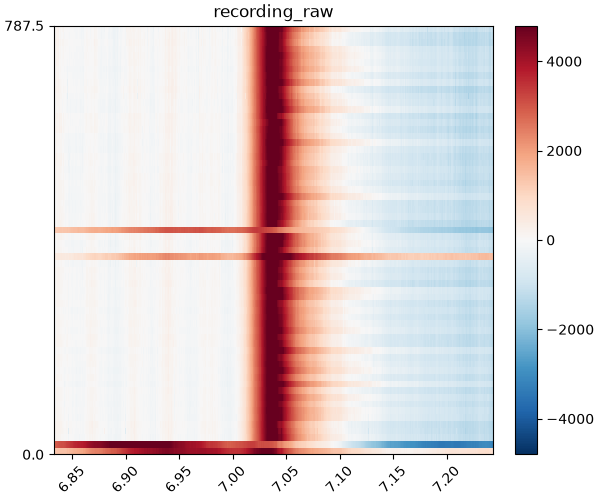

In [38]:
plot_prepro(
    {"recording_raw": recording},
    time_range=SAT_TIME_RANGE,
    clim=(-4800, 4800)
)

In [39]:
w = sw.plot_traces(
    dict(cmr=recording_cmr, zeroed=recording_zeroed),
    mode="map",
    time_range=SAT_TIME_RANGE,
    clim=(-300, 300)
)

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

### Step 6: Motion estimation and assessment

Shank-like probes, when implanted *in vivo* and mostly in acute settings, can experience "drift", aka relative motion between the probe and the neurons.

This makes waveforms change (A), which is a nightmare for spike sorting (since they rely on similarity between waveforms...). Some sorters can partially correct for motion, but it's been showed that when motion is present, spike sorting results are strongly affected, no matter the correction (see [Garcia et. al 2024](https://www.eneuro.org/content/11/2/ENEURO.0229-23.2023.abstract) for more details).

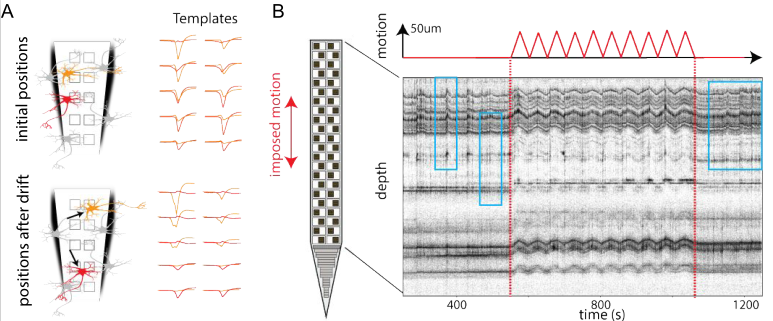

What can we do? At the very least, we should assess whether motion is a problem for our dataset.

Algorithms out there include Kilosort’s drift correction (`kilosort-like` in SpikeInterface), [DREDge](https://www.nature.com/articles/s41592-025-02614-5) and [MEDiCINe](https://www.eneuro.org/content/12/3/ENEURO.0529-24.2025). SpikeInterface exposes these through the [`compute_motion()`](https://spikeinterface.readthedocs.io/en/latest/api.html#spikeinterface.preprocessing.compute_motion) and [`correct_motion()`](https://spikeinterface.readthedocs.io/en/latest/api.html#spikeinterface.preprocessing.correct_motion) functions that use convenient presets which define how motion estimation and interpolation (aka correction) is run.

Today we will use `dredge_fast` and set `output_motion_info=True` so we can inspect the results of motion correction.

Typically, non-rigid estimation algorithms break up the probe into sections and perform rigid alignment within each. Because this Cambridge Neurotech probe has only 64 channels, non-rigid estimation does not perform as well, and so we will turn it off (a full list of these arguments can be found here):

In [40]:
spre.get_motion_presets()

['dredge',
 'medicine',
 'dredge_fast',
 'nonrigid_accurate',
 'nonrigid_fast_and_accurate',
 'rigid_fast',
 'kilosort_like']

In [41]:
motion_folder = results_folder / "motion_dredge"

In [42]:
rec_corrected, motion_info = spre.correct_motion(
    recording_cmr,
    preset="dredge_fast",
    output_motion_info=True,
    # turn off non-rigid estimation
    estimate_motion_kwargs={"rigid": True},
    folder=motion_folder
)
print(rec_corrected)

noise_level (workers: 4 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

detect and localize (workers: 4 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

Cross correlation:   0%|          | 0/1 [00:00<?, ?it/s]

interpolate_motion (InterpolateMotionRecording): 60 channels - 20.0kHz - 1 segments 
                    1,800,000 samples - 90.00s (1.50 minutes) - float32 dtype - 411.99 MiB


In [43]:
motion_info.keys()

dict_keys(['parameters', 'run_times', 'peaks', 'peak_locations', 'motion'])

In [44]:
motion = motion_info["motion"]

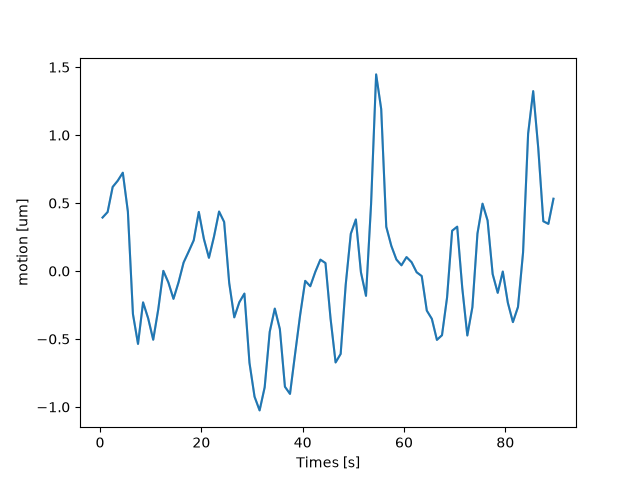

In [45]:
# plot motion and rastermap
_ = sw.plot_motion(motion, backend="matplotlib")

Text(0.5, 0.98, 'Motion correction output')

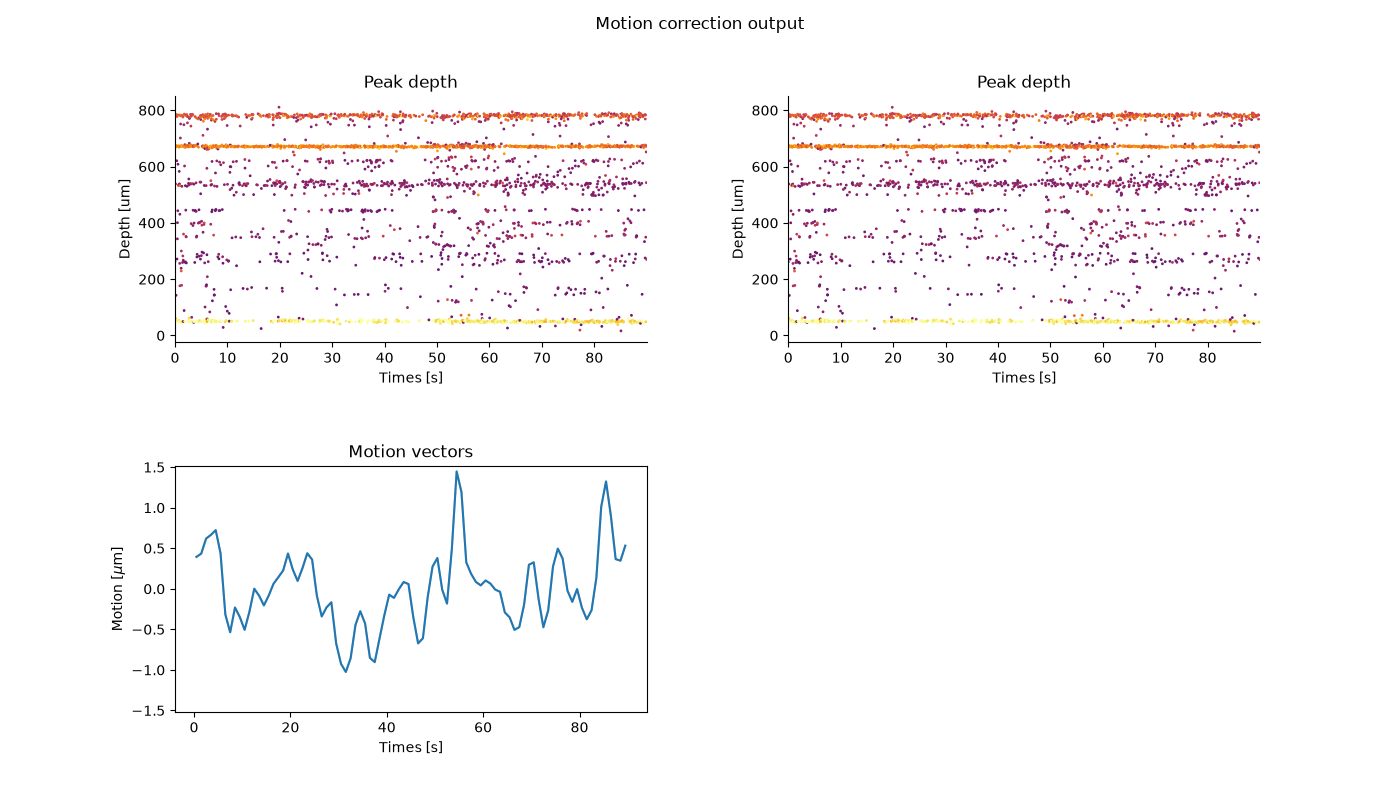

In [46]:
# Display the motion output: drift map + estimated motion over depth/time.
fig = plt.figure(figsize=(14, 8))
sw.plot_motion_info(
    motion_info,
    recording=rec_corrected,
    figure=fig,
    color_amplitude=True,
    amplitude_cmap="inferno",
    scatter_decimate=10,
    backend="matplotlib"
)
fig.suptitle("Motion correction output")

### Step 6: Save preprocessed recording

Now that we have finalized our *lazy* preprocessing chain, we can save a preprocessed version to a binary file (or a [Zarr](https://zarr.readthedocs.io/en/stable/) folder). Downstream steps, like spike sorting and postprocessing, will need access to the preprocessed traces. In order to avoid preprocessing "on-the-fly" several times, we can dump the preprocessed data to a file.

This operation (and many others) can be performed in parallel, using multiple CPUs to crunch chunks of the traces. All the parallel operations are controlled by the `job_kwargs`. Let's take a look at them and set them globally:

In [47]:
recording_preprocessed = recording_cmr

In [48]:
si.get_global_job_kwargs()

{'pool_engine': 'process',
 'n_jobs': 4,
 'chunk_duration': '1s',
 'progress_bar': True,
 'mp_context': None,
 'max_threads_per_worker': 1}

In [49]:
si.set_global_job_kwargs(chunk_duration="2s")

In [50]:
si.get_global_job_kwargs()

{'pool_engine': 'process',
 'n_jobs': 4,
 'chunk_duration': '2s',
 'progress_bar': True,
 'mp_context': None,
 'max_threads_per_worker': 1}

In [51]:
recording_preprocessed

CommonReferenceRecording: 60 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                          90.00s (1.50 minutes) - int16 dtype - 205.99 MiB

In [52]:
preprocessed_bin_folder = results_folder / "preprocessed"

recording_binary = recording_preprocessed.save(folder=preprocessed_bin_folder, format="binary")
recording_binary

write_binary (workers: 4 processes fork):   0%|          | 0/45 [00:00<?, ?it/s]

BinaryFolderRecording: 60 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                       90.00s (1.50 minutes) - int16 dtype - 205.99 MiB